In [53]:
import numpy as np
import matplotlib.pyplot as plt

In [54]:
### Dados do experimento:

K = 100          # mD - Permeabilidade absoluta
d = 3.2          # cm - diâmetro da amostra poroso
L = 10           # cm - comprimento da amostra
phi = 0.2        # adimensional - porosidade
mu_w = 1.1       # cP - viscosidade da água
mu_o = 5         # cP - viscosidade do óleo

In [55]:
### Volume cilindro

vol = np.pi * (d/2)**2 * l
print('O volume da amostra é, ', vol, 'cm³')

## Volume de poroso:

vol_por = phi * vol
print('O volume poroso é, ', vol_por, 'cm³')

### Área da seção
area = np.pi * (d/2)**2
print('A área da seção é, ', area, 'cm²')

O volume da amostra é,  80.4247719318987 cm³
O volume poroso é,  16.084954386379742 cm³
A área da seção é,  8.042477193189871 cm²


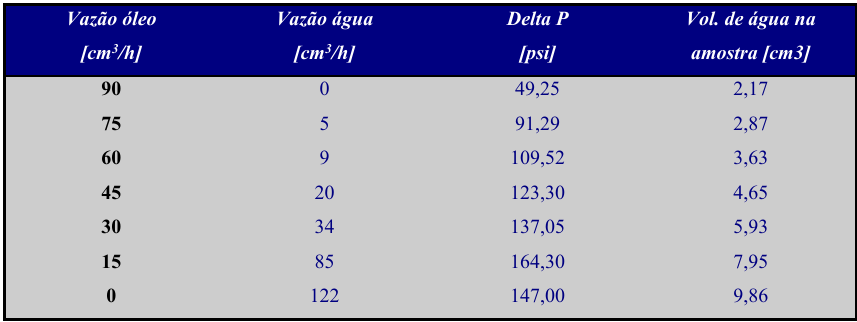

In [56]:
### vetor óleo

vazao_oleo = np.array([90, 75, 60, 45, 30, 15, 0])
vazao_agua = np.array([0,   5,  9, 20, 34, 85, 122])
deltaP =     np.array([49.25, 91.29, 109.52, 123.30, 137.05, 164.30, 147])
vol_agua =  np.array([2.17, 2.87, 3.63, 4.65, 5.93, 7.95, 9.86])

In [57]:
### Cálculo da saturação de água
Sw = vol_agua / vol_por

print('Sw = ', Sw)

### Cálculo da saturação de óleo
So = 1 - Sw

print('So = ', So)

Sw =  [0.13490868 0.17842761 0.22567674 0.28909003 0.3686675  0.4942507
 0.61299521]
So =  [0.86509132 0.82157239 0.77432326 0.71090997 0.6313325  0.5057493
 0.38700479]


  $$Q_{w} = \frac{K \cdot K_{rw}(Sw)}{\mu_{w}}\cdot A \cdot \frac{\Delta P}{L} \hspace{1cm} \rightarrow \hspace{1cm} K_{rw}(Sw) = \frac{Q_{w}\cdot \mu_{w} \cdot L}{K \cdot A \cdot \Delta p} $$

  

  $$Q_{o} = \frac{K \cdot K_{ro}(Sw)}{\mu_{o}}\cdot A \cdot \frac{\Delta P}{L} \hspace{1cm} \rightarrow \hspace{1cm} K_{ro}(Sw) = \frac{Q_{o}\cdot \mu_{o} \cdot L}{K \cdot A \cdot \Delta p}$$

In [61]:
### Conversão de unidades para Darcy

Q_w = vazao_agua / 3600            # cm³/h -> cm³/s
Q_o = vazao_oleo / 3600            # cm³/h -> cm³/s
K_darcy = K /1000                  # mD -> D
delta_P_darcy = deltaP / 14.696    # psi -> atm

In [62]:
### Cálculo da permeabilidade

krw = Q_w * mu_w * L / (K_darcy * area * delta_P_darcy)
kro = Q_o * mu_o * L / (K_darcy * area * delta_P_darcy)

print('krw = ', krw)
print('kro = ', kro)

krw =  [0.         0.00305806 0.00458827 0.00905663 0.01385158 0.02888556
 0.0463385 ]
kro =  [0.46378114 0.20850423 0.13903836 0.09262458 0.05555447 0.02317024
 0.        ]


In [75]:
### Saturação inicial de água
Swi = Sw[0]

### Saturação residual de óleo
Sor = 1 - So[-1]

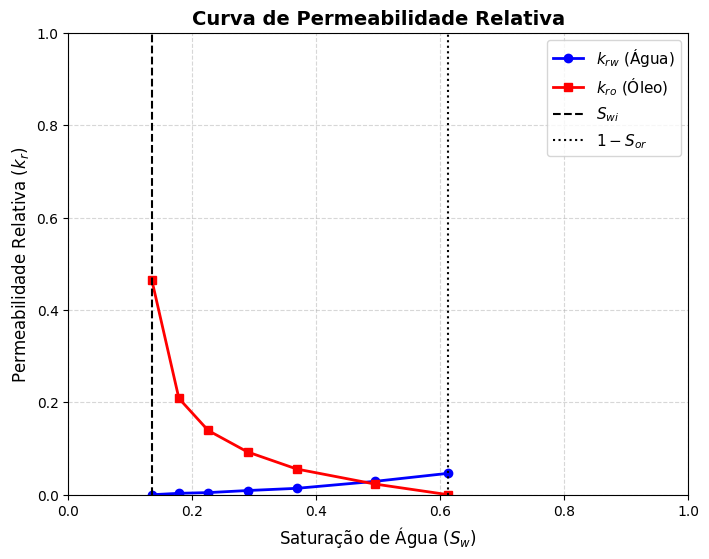

In [83]:
### Construção do gráfico das permeabilidades relativas

plt.figure(figsize=(8, 6))

# Plotando as curvas de permeabilidade relativa do óleo e da água
plt.plot(Sw, krw, label='$k_{rw}$ (Água)', color='blue', marker='o', linewidth=2)
plt.plot(Sw, kro, label='$k_{ro}$ (Óleo)', color='red', marker='s', linewidth=2)

# Configurações de títulos e eixos
plt.title('Curva de Permeabilidade Relativa', fontsize=14, fontweight='bold')
plt.xlabel('Saturação de Água ($S_w$)', fontsize=12)
plt.ylabel('Permeabilidade Relativa ($k_r$)', fontsize=12)

# Marcando os valores de Swi e Sor com tracejados
plt.axvline(Swi, color='black', linestyle='--', label=r'$S_{wi}$')
plt.axvline(Sor, color='black', linestyle=':', label=r'$1 - S_{or}$')

# Ajustes de limites e visualização
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(fontsize=11, loc='best')

# Exibindo o gráfico
plt.show()